# Milestone 4: Hydrogeological Feature Engineering, Spatial/Temporal Structure & Baseline Analytics

**Purpose:** Understand the actual spatial and temporal structure of normalized groundwater data and create scientifically defensible reusable features and baseline analytics.

**Governing Standard:** [instruction.md](file:///d:/Projects%20ALL/DWLR_GRW_INDIA/instruction.md)

**Scientific Constraints:**
- All features derived from real normalized data only
- No future leakage in temporal features
- India water-level unit remains UNKNOWN
- Maharashtra water-level unit is meter (from source header)
- Reference datum remains UNKNOWN for both datasets
- status_raw and trend_raw are NOT used as ground truth


In [3]:
# Section 1: Environment & Path Resolution
import os
import sys
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (14, 6)
matplotlib.rcParams['figure.dpi'] = 100

# Path resolution
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

INDIA_PARQUET = os.path.join(PROJECT_ROOT, 'data', 'processed', 'india', 'india_normalized.parquet')
MH_PARQUET = os.path.join(PROJECT_ROOT, 'data', 'processed', 'maharashtra', 'maharashtra_normalized.parquet')

print(f'Project root: {PROJECT_ROOT}')
print(f'India parquet exists: {os.path.exists(INDIA_PARQUET)}')
print(f'Maharashtra parquet exists: {os.path.exists(MH_PARQUET)}')


Project root: d:\Projects ALL\DWLR_GRW_INDIA\NEW
India parquet exists: True
Maharashtra parquet exists: True


## 2. Load Normalized Datasets


In [4]:
# Load normalized datasets from Milestone 3
df_india = pd.read_parquet(INDIA_PARQUET)
df_mh = pd.read_parquet(MH_PARQUET)

# Filter to analytics-ready subsets
india_ar = df_india[df_india['is_analytics_ready'] == True].copy()
mh_ar = df_mh[df_mh['is_analytics_ready'] == True].copy()

print(f'India: {len(df_india):,} total rows, {len(india_ar):,} analytics-ready')
print(f'Maharashtra: {len(df_mh):,} total rows, {len(mh_ar):,} analytics-ready')
print()
print('India columns:', list(india_ar.columns))
print()
print('Maharashtra columns:', list(mh_ar.columns))


India: 1,569,168 total rows, 1,542,448 analytics-ready
Maharashtra: 218,791 total rows, 210,670 analytics-ready

India columns: ['source_dataset', 'source_file', 'observation_type', 'candidate_site_id', 'state', 'district', 'block', 'village', 'latitude', 'longitude', 'source_lat', 'source_lng', 'coordinate_inverted_corrected', 'observation_date', 'observation_year', 'observation_month', 'water_level_raw', 'water_level_unit', 'water_level_reference', 'reference_datum', 'status_raw', 'trend_raw', 'state_raw', 'district_raw', 'block_raw', 'village_raw', 'date_raw', 'quality_flags', 'is_analytics_ready']

Maharashtra columns: ['source_dataset', 'source_file', 'observation_type', 'candidate_site_id', 'station_name', 'state', 'state_lgd_code', 'district', 'district_lgd_code', 'subdistrict', 'latitude', 'longitude', 'source_lat', 'source_lng', 'coordinate_inverted_corrected', 'elevation_msl', 'observation_timestamp', 'observation_date', 'water_level_raw', 'water_level_unit', 'water_level_ref

## 3. Schema and Temporal Overview


In [5]:
from src.features.temporal import compute_india_temporal_profile, compute_maharashtra_temporal_profile

india_temporal = compute_india_temporal_profile(india_ar)
mh_temporal = compute_maharashtra_temporal_profile(mh_ar)

print('=== INDIA TEMPORAL PROFILE ===')
print(f"Date range: {india_temporal['date_range']['min']} to {india_temporal['date_range']['max']}")
print(f"Span: {india_temporal['date_range']['span_days']:,} days ({india_temporal['date_range']['span_days']/365.25:.1f} years)")
print(f"Unique years: {india_temporal['year_distribution']['unique_years']}")
print(f"Months observed: {india_temporal['month_distribution']['unique_months']}")
print(f"Per-site year coverage: min={india_temporal['per_site_year_coverage']['min_years']}, "
      f"max={india_temporal['per_site_year_coverage']['max_years']}, "
      f"median={india_temporal['per_site_year_coverage']['median_years']}")
print()
print('=== MAHARASHTRA TEMPORAL PROFILE ===')
print(f"Timestamp range: {mh_temporal['timestamp_range']['min']} to {mh_temporal['timestamp_range']['max']}")
print(f"Span: {mh_temporal['timestamp_range']['span_days']:,} days")
print(f"Total stations: {mh_temporal['observations_per_station']['total_stations']}")
print(f"Telemetry interval (hrs): median={mh_temporal['telemetry_interval_hours']['median']}, "
      f"pct 6-hourly={mh_temporal['telemetry_interval_hours']['pct_6_hourly']}%")


=== INDIA TEMPORAL PROFILE ===
Date range: 1994-01-01 to 2024-05-10
Span: 11,087 days (30.4 years)
Unique years: 31
Months observed: [1, 3, 4, 5, 8, 11]
Per-site year coverage: min=1, max=31, median=10.0

=== MAHARASHTRA TEMPORAL PROFILE ===
Timestamp range: 2026-01-01 00:00:00 to 2026-05-30 00:00:00
Span: 149 days
Total stations: 1012
Telemetry interval (hrs): median=6.0, pct 6-hourly=87.5%


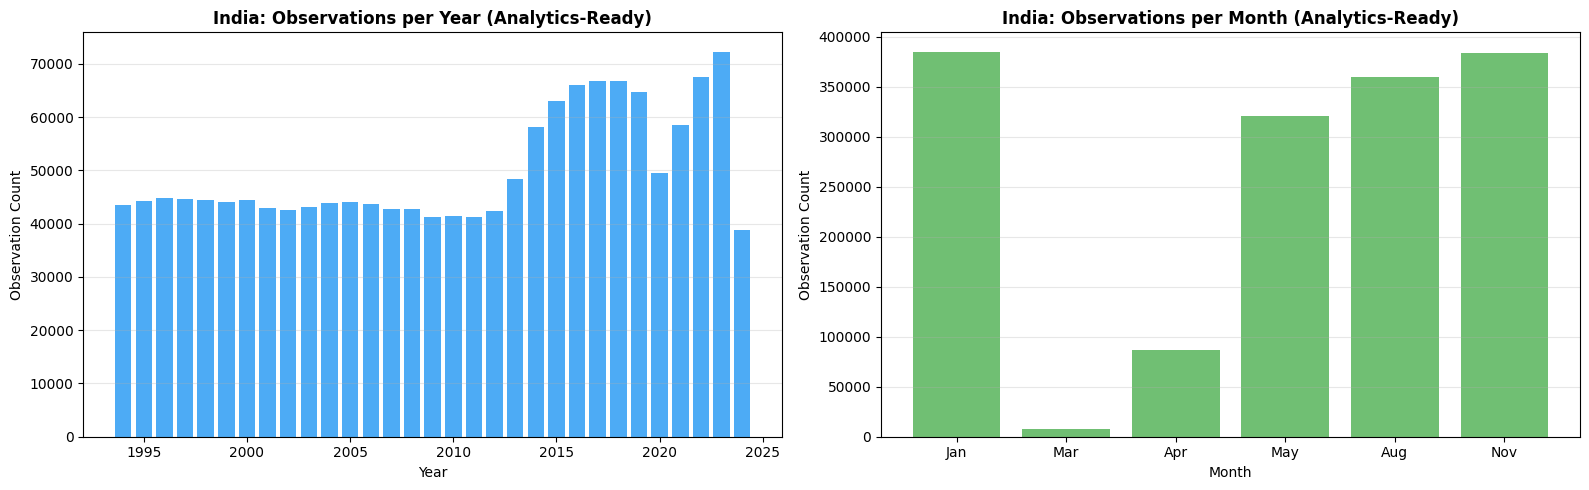

In [6]:
# Year distribution plot (India)
year_counts = india_ar['observation_year'].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(year_counts.index, year_counts.values, color='#2196F3', alpha=0.8)
axes[0].set_title('India: Observations per Year (Analytics-Ready)', fontweight='bold')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Observation Count')
axes[0].grid(axis='y', alpha=0.3)

# Month distribution
month_counts = india_ar['observation_month'].value_counts().sort_index()
month_labels = {1:'Jan', 3:'Mar', 4:'Apr', 5:'May', 8:'Aug', 11:'Nov'}
axes[1].bar([month_labels.get(m, str(m)) for m in month_counts.index], month_counts.values, 
            color='#4CAF50', alpha=0.8)
axes[1].set_title('India: Observations per Month (Analytics-Ready)', fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Observation Count')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Spatial/Location Analysis

The India dataset lacks an official station ID. We investigate whether the `candidate_site_id` 
(SHA-256 hash of state+district+block+village+lat_4dp+lng_4dp) reliably represents repeated 
physical monitoring locations.


In [7]:
from src.features.spatial import (
    build_analytical_site_id, analyze_location_consistency, 
    compute_site_observation_summary, evaluate_spatial_clustering_necessity
)

# Location consistency analysis
consistency = analyze_location_consistency(india_ar)

print('=== LOCATION CONSISTENCY ANALYSIS ===')
print(f"Total unique candidate sites: {consistency['total_unique_candidate_sites']:,}")
print(f"Sites with single coord pair: {consistency['sites_with_single_coord_pair']:,}")
print(f"Sites with multiple coord pairs: {consistency['sites_with_multiple_coord_pairs']:,}")
print()
print('Observations per site:')
for k, v in consistency['observations_per_site'].items():
    print(f"  {k}: {v}")
print()
print('Admin field completeness:')
for k, v in consistency['admin_field_completeness'].items():
    print(f"  {k}: {v:,}")
if 'admin_groups_with_multiple_coordinates' in consistency:
    print(f"\nAdmin groups with multiple coordinates: {consistency['admin_groups_with_multiple_coordinates']:,}")


=== LOCATION CONSISTENCY ANALYSIS ===
Total unique candidate sites: 40,841
Sites with single coord pair: 40,815
Sites with multiple coord pairs: 26

Observations per site:
  min: 1
  max: 135
  mean: 37.8
  median: 26.0
  std: 37.7
  sites_with_1_obs: 2799
  sites_with_2_to_5_obs: 7295
  sites_with_6_to_20_obs: 8147
  sites_with_21_plus_obs: 22600

Admin field completeness:
  state_non_null: 1,542,448
  district_non_null: 1,540,953
  block_non_null: 1,536,499
  village_non_null: 1,538,987
  total_rows: 1,542,448

Admin groups with multiple coordinates: 4,339


## 5. Location Consistency and Repeated-Site Analysis


Total analytical sites: 40,841
Sites with >= 10 observations: 27,585
Sites with >= 20 observations: 23,004



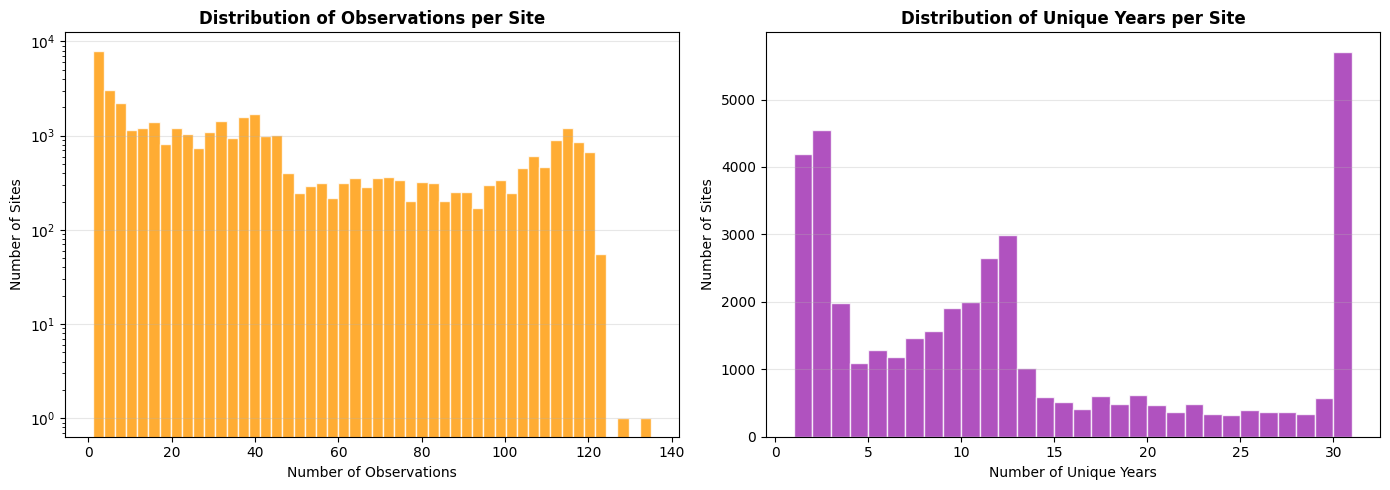

In [8]:
# Site observation summary
site_summary = compute_site_observation_summary(india_ar)
print(f'Total analytical sites: {len(site_summary):,}')
print(f'Sites with >= 10 observations: {(site_summary["total_observations"] >= 10).sum():,}')
print(f'Sites with >= 20 observations: {(site_summary["total_observations"] >= 20).sum():,}')
print()

# Observation count distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(site_summary['total_observations'], bins=50, color='#FF9800', alpha=0.8, edgecolor='white')
axes[0].set_title('Distribution of Observations per Site', fontweight='bold')
axes[0].set_xlabel('Number of Observations')
axes[0].set_ylabel('Number of Sites')
axes[0].set_yscale('log')
axes[0].grid(axis='y', alpha=0.3)

# Year coverage per site
axes[1].hist(site_summary['unique_years'], bins=30, color='#9C27B0', alpha=0.8, edgecolor='white')
axes[1].set_title('Distribution of Unique Years per Site', fontweight='bold')
axes[1].set_xlabel('Number of Unique Years')
axes[1].set_ylabel('Number of Sites')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:
# Spatial clustering evaluation
clustering_eval = evaluate_spatial_clustering_necessity(india_ar)
print('=== SPATIAL CLUSTERING EVALUATION ===')
print(f"Unique coordinate pairs: {clustering_eval['unique_coordinate_pairs']:,}")
print(f"Candidate site IDs: {clustering_eval['candidate_site_ids']:,}")
print(f"Coordinate precision: ~{clustering_eval['coordinate_precision_meters']}m")
print(f"Clustering justified: {clustering_eval['clustering_justified']}")
print(f"Reason: {clustering_eval['reason']}")
print(f"\nRecommendation: {clustering_eval['recommendation']}")


=== SPATIAL CLUSTERING EVALUATION ===
Unique coordinate pairs: 39,363
Candidate site IDs: 40,841
Coordinate precision: ~11.1m
Clustering justified: False
Reason: Clustering at 100.0m radius would merge distinct monitoring locations that may represent different wells in the same village/block. Without authoritative station metadata to confirm which wells are the same physical monitoring point, clustering would introduce unverifiable assumptions. The candidate_site_id provides a safer analytical location key at ~11m coordinate precision.

Recommendation: Use candidate_site_id (promoted as analytical_site_id) as the primary location identifier. It is deterministic, reproducible, and does not require unverifiable clustering assumptions. Clearly document that it is an analytical identifier, not an official station ID.


## 6. Temporal Coverage and Observation Gaps


=== INDIA OBSERVATION GAPS (sites with 10+ obs) ===
Sites analyzed: 5,000
Median gap (days): min=61, max=733, mean=116
Max gap (days): min=120, max=9890, mean=664


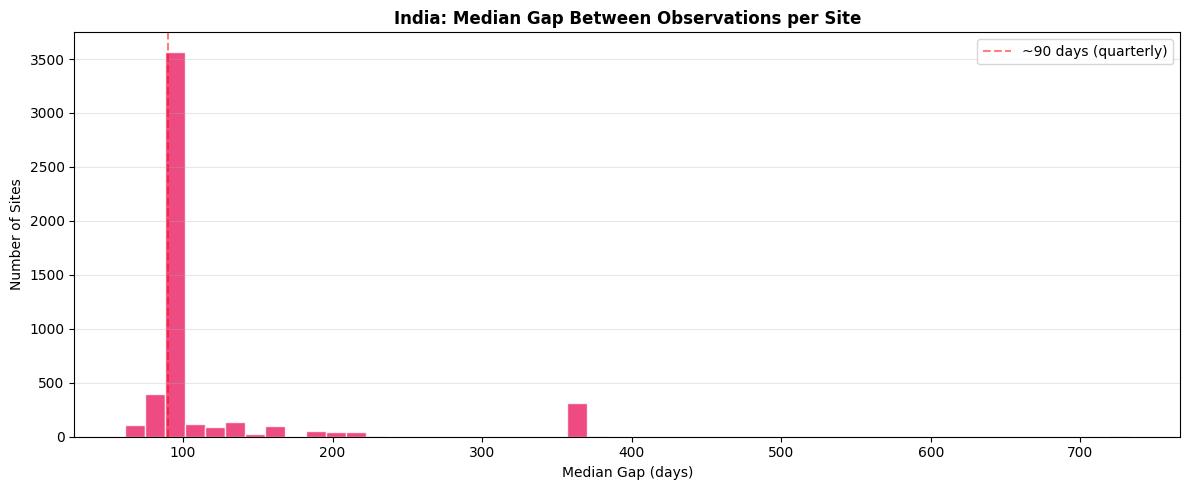

In [10]:
from src.features.temporal import compute_observation_gaps

# India observation gaps (sample for efficiency)
sites_with_enough = india_ar.groupby('candidate_site_id').size()
sites_10plus = sites_with_enough[sites_with_enough >= 10].index.tolist()
india_sample = india_ar[india_ar['candidate_site_id'].isin(sites_10plus[:5000])]

india_gaps = compute_observation_gaps(india_sample)
valid_gaps = india_gaps.dropna(subset=['median_gap_days'])

print('=== INDIA OBSERVATION GAPS (sites with 10+ obs) ===')
print(f'Sites analyzed: {len(valid_gaps):,}')
print(f'Median gap (days): min={valid_gaps["median_gap_days"].min():.0f}, '
      f'max={valid_gaps["median_gap_days"].max():.0f}, '
      f'mean={valid_gaps["median_gap_days"].mean():.0f}')
print(f'Max gap (days): min={valid_gaps["max_gap_days"].min():.0f}, '
      f'max={valid_gaps["max_gap_days"].max():.0f}, '
      f'mean={valid_gaps["max_gap_days"].mean():.0f}')

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(valid_gaps['median_gap_days'], bins=50, color='#E91E63', alpha=0.8, edgecolor='white')
ax.set_title('India: Median Gap Between Observations per Site', fontweight='bold')
ax.set_xlabel('Median Gap (days)')
ax.set_ylabel('Number of Sites')
ax.axvline(x=90, color='red', linestyle='--', alpha=0.5, label='~90 days (quarterly)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
# Maharashtra telemetry gaps
mh_gaps = compute_observation_gaps(
    mh_ar, site_col='station_name', 
    timestamp_col='observation_timestamp'
)
mh_valid_gaps = mh_gaps.dropna(subset=['median_gap_days'])

print('=== MAHARASHTRA TELEMETRY GAPS ===')
print(f'Stations analyzed: {len(mh_valid_gaps):,}')
# Convert to hours for telemetry
print(f'Median gap (hours): min={mh_valid_gaps["median_gap_days"].min()*24:.1f}, '
      f'max={mh_valid_gaps["median_gap_days"].max()*24:.1f}, '
      f'mean={mh_valid_gaps["median_gap_days"].mean()*24:.1f}')


=== MAHARASHTRA TELEMETRY GAPS ===
Stations analyzed: 1,008
Median gap (hours): min=6.0, max=408.0, mean=6.6


## 7. Seasonal Structure

India observations occur in 6 months: January, March, April, May, August, November.  
Seasonal labels are analytical convenience labels based on Indian meteorological conventions,  
NOT official CGWB season codes.


In [12]:
from src.features.seasonal import (
    assign_india_season, compute_seasonal_statistics,
    compute_seasonal_anomaly, compute_yoy_seasonal_change,
    INDIA_MONTH_TO_SEASON
)

print('Analytical season mapping:')
for month, season in sorted(INDIA_MONTH_TO_SEASON.items()):
    count = (india_ar['observation_month'] == month).sum()
    print(f'  Month {month:2d} -> {season:25s} ({count:,} observations)')

# Assign seasons
india_seasonal = assign_india_season(india_ar)
print(f'\nSeason distribution:')
print(india_seasonal['analytical_season'].value_counts().to_string())


Analytical season mapping:
  Month  1 -> RABI_WINTER               (385,074 observations)
  Month  3 -> PRE_MONSOON_EARLY         (7,296 observations)
  Month  4 -> PRE_MONSOON               (86,653 observations)
  Month  5 -> PRE_MONSOON               (320,817 observations)
  Month  8 -> MONSOON                   (359,439 observations)
  Month 11 -> POST_MONSOON              (383,169 observations)

Season distribution:
analytical_season
PRE_MONSOON          407470
RABI_WINTER          385074
POST_MONSOON         383169
MONSOON              359439
PRE_MONSOON_EARLY      7296


Site-season groups with >= 5 observations: 95,061



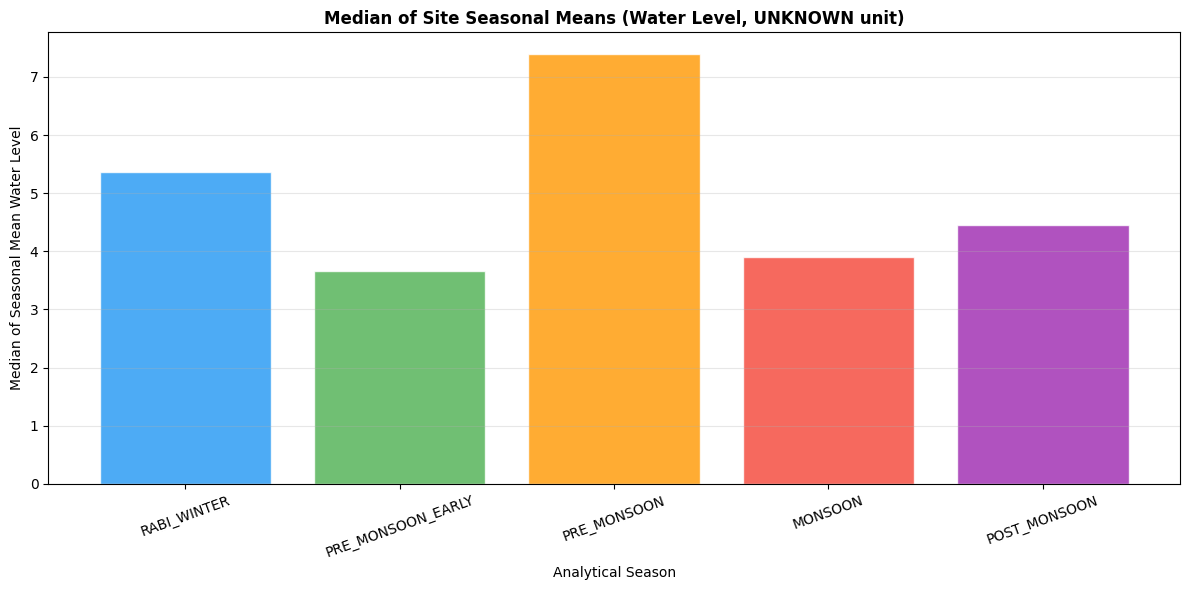

In [13]:
# Seasonal statistics per site
seasonal_stats = compute_seasonal_statistics(india_seasonal, min_observations=5)
print(f'Site-season groups with >= 5 observations: {len(seasonal_stats):,}')
print()

# Seasonal water level patterns
fig, ax = plt.subplots(figsize=(12, 6))
season_order = ['RABI_WINTER', 'PRE_MONSOON_EARLY', 'PRE_MONSOON', 'MONSOON', 'POST_MONSOON']
season_means = []
for s in season_order:
    subset = seasonal_stats[seasonal_stats['analytical_season'] == s]
    if len(subset) > 0:
        season_means.append(subset['seasonal_mean'].median())
    else:
        season_means.append(np.nan)

colors = ['#2196F3', '#4CAF50', '#FF9800', '#F44336', '#9C27B0']
bars = ax.bar(season_order, season_means, color=colors, alpha=0.8, edgecolor='white')
ax.set_title('Median of Site Seasonal Means (Water Level, UNKNOWN unit)', fontweight='bold')
ax.set_ylabel('Median of Seasonal Mean Water Level')
ax.set_xlabel('Analytical Season')
plt.xticks(rotation=20)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:
# Coverage: how many sites have all 4 main seasons?
site_season_counts = india_seasonal.groupby('candidate_site_id')['analytical_season'].nunique()
print('Number of unique seasons per site:')
print(site_season_counts.value_counts().sort_index().to_string())
print(f'\nSites with all 4 main seasons (Jan/May/Aug/Nov): ', end='')
main_seasons = {'RABI_WINTER', 'PRE_MONSOON', 'MONSOON', 'POST_MONSOON'}
sites_all_main = india_seasonal.groupby('candidate_site_id')['analytical_season'].apply(
    lambda x: main_seasons.issubset(set(x))
).sum()
print(f'{sites_all_main:,}')


Number of unique seasons per site:
analytical_season
1     9510
2     2483
3     2161
4    26330
5      357

Sites with all 4 main seasons (Jan/May/Aug/Nov): 26,241


## 8. Lag/Rolling Feature Analysis

**India:** Median gap ~78-92 days. "Previous observation" lag is the most defensible.
Calendar-based lags (e.g., "3-month lag") require validation that the dates actually support
that interpretation.

**Maharashtra:** 6-hourly telemetry supports short-term lags (6h, 12h, 24h, 48h).


In [15]:
from src.features.trends import compute_rate_of_change

# India: Rate of change analysis
india_roc_sample = india_seasonal[india_seasonal['candidate_site_id'].isin(sites_10plus[:2000])]
india_roc = compute_rate_of_change(india_roc_sample)

valid_days = india_roc['days_since_prev'].dropna()
print('=== INDIA LAG ANALYSIS ===')
print(f'Observations with prior obs: {len(valid_days):,}')
print(f'Days since previous obs: min={valid_days.min():.0f}, '
      f'median={valid_days.median():.0f}, max={valid_days.max():.0f}')
print()
print('Distribution of lag intervals (days):')
bins = [0, 30, 60, 90, 120, 150, 200, 365, 1000]
labels_b = ['0-30', '30-60', '60-90', '90-120', '120-150', '150-200', '200-365', '365+']
lag_bins = pd.cut(valid_days, bins=bins, labels=labels_b)
print(lag_bins.value_counts().sort_index().to_string())
print()
print('CONCLUSION: India observations are primarily ~90 day (seasonal) intervals.')
print('"Previous observation" lag is the most defensible. Do NOT label it as 3-month lag')
print('without verifying actual date differences per pair.')


=== INDIA LAG ANALYSIS ===
Observations with prior obs: 108,095
Days since previous obs: min=0, median=92, max=9890

Distribution of lag intervals (days):
days_since_prev
0-30          55
30-60       3698
60-90      38578
90-120     34992
120-150    17808
150-200     4427
200-365     6533
365+        1601

CONCLUSION: India observations are primarily ~90 day (seasonal) intervals.
"Previous observation" lag is the most defensible. Do NOT label it as 3-month lag
without verifying actual date differences per pair.


In [16]:
# Maharashtra: Lag analysis for telemetry
mh_roc = compute_rate_of_change(
    mh_ar, site_col='station_name', date_col='observation_timestamp'
)

mh_valid_days = mh_roc['days_since_prev'].dropna()
mh_hours = mh_valid_days * 24
print('=== MAHARASHTRA LAG ANALYSIS ===')
print(f'Observations with prior obs: {len(mh_valid_days):,}')
print(f'Hours since previous obs: min={mh_hours.min():.1f}, '
      f'median={mh_hours.median():.1f}, max={mh_hours.max():.1f}')
print(f'Pct exactly 6 hours: {(abs(mh_hours - 6.0) < 0.5).mean()*100:.1f}%')
print()
print('CONCLUSION: Maharashtra telemetry is predominantly 6-hourly.')
print('Suitable short-term lags: 1-step (6h), 2-step (12h), 4-step (24h), 8-step (48h).')


=== MAHARASHTRA LAG ANALYSIS ===
Observations with prior obs: 209,658
Hours since previous obs: min=0.1, median=6.0, max=2160.0
Pct exactly 6 hours: 86.6%

CONCLUSION: Maharashtra telemetry is predominantly 6-hourly.
Suitable short-term lags: 1-step (6h), 2-step (12h), 4-step (24h), 8-step (48h).


## 9. Trend Analysis

Linear trends computed using OLS. Direction labels are neutral:
INCREASING, DECREASING, STABLE, NOT_SIGNIFICANT.

**No physical interpretation** (e.g., "groundwater depletion") is applied
because the reference datum is UNKNOWN.


In [17]:
from src.features.trends import compute_location_trend

# Compute trends for sites with sufficient data
trends = compute_location_trend(india_ar, min_observations=10, min_years_span=5)
print(f'Sites with computable trends (>=10 obs, >=5yr span): {len(trends):,}')
print()
print('Trend direction distribution:')
print(trends['trend_direction'].value_counts().to_string())
print()
print('Slope per year statistics (unit/year, unit UNKNOWN):')
print(f'  Mean: {trends["slope_per_year"].mean():.4f}')
print(f'  Median: {trends["slope_per_year"].median():.4f}')
print(f'  Std: {trends["slope_per_year"].std():.4f}')
print()
print('R-squared distribution:')
print(f'  Mean: {trends["r_squared"].mean():.4f}')
print(f'  Median: {trends["r_squared"].median():.4f}')
print()
print('NOTE: Low R-squared indicates that linear trend explains little variance.')
print('Many sites show seasonal variation rather than monotonic trends.')


Sites with computable trends (>=10 obs, >=5yr span): 26,162

Trend direction distribution:
trend_direction
NOT_SIGNIFICANT    16134
INCREASING          5650
DECREASING          4378

Slope per year statistics (unit/year, unit UNKNOWN):
  Mean: 0.0402
  Median: 0.0023
  Std: 0.4446

R-squared distribution:
  Mean: 0.1438
  Median: 0.0483

NOTE: Low R-squared indicates that linear trend explains little variance.
Many sites show seasonal variation rather than monotonic trends.


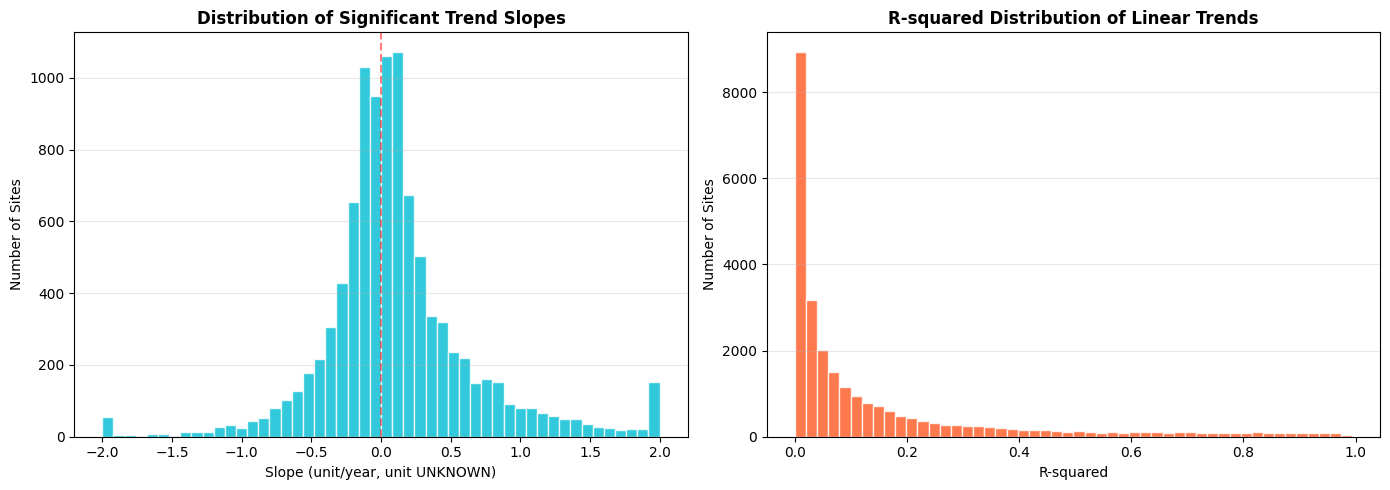

In [18]:
# Trend visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Slope distribution
significant = trends[trends['trend_direction'] != 'NOT_SIGNIFICANT']
axes[0].hist(significant['slope_per_year'].clip(-2, 2), bins=50, 
             color='#00BCD4', alpha=0.8, edgecolor='white')
axes[0].axvline(x=0, color='red', linestyle='--', alpha=0.5)
axes[0].set_title('Distribution of Significant Trend Slopes', fontweight='bold')
axes[0].set_xlabel('Slope (unit/year, unit UNKNOWN)')
axes[0].set_ylabel('Number of Sites')
axes[0].grid(axis='y', alpha=0.3)

# R-squared distribution
axes[1].hist(trends['r_squared'], bins=50, color='#FF5722', alpha=0.8, edgecolor='white')
axes[1].set_title('R-squared Distribution of Linear Trends', fontweight='bold')
axes[1].set_xlabel('R-squared')
axes[1].set_ylabel('Number of Sites')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Statistical Anomaly/Index Investigation

### SGI Decision: **REJECTED**

The Standardized Groundwater Index (SGI) is NOT scientifically justified for this dataset:
1. Observations occur in only 6 months, not monthly
2. Month 3 (March) has very limited data
3. Many sites have incomplete seasonal coverage
4. Reference datum is UNKNOWN

**Alternative: `seasonal_z_score`** — a simple standardized anomaly within each (site, season) group.
This is a statistical measure, NOT a drought or stress index.


In [19]:
from src.features.anomaly import compute_seasonal_z_score, SGI_REJECTION_REASON

print(SGI_REJECTION_REASON)



SGI (Standardized Groundwater Index) is NOT scientifically justified for this dataset.

Reasons:
1. TEMPORAL IRREGULARITY: Observations occur in only 6 months [1, 3, 4, 5, 8, 11],
   not the monthly frequency required by standard SGI methodology.
2. INSUFFICIENT MONTH 3 DATA: Only 7,296 observations in March (0.47% of total),
   making March seasonal statistics unreliable for many sites.
3. INCOMPLETE COVERAGE: Many sites lack observations for all seasons across all years,
   violating the assumption of comparable seasonal distributions needed for SGI.
4. UNKNOWN REFERENCE DATUM: Without confirmed physical meaning of the water level
   values, the standardized index cannot be reliably interpreted as a groundwater
   stress indicator.
5. MIXED OBSERVATION TYPES: Pre-monsoon vs monsoon vs post-monsoon observations
   represent fundamentally different hydrological states. SGI typically requires
   within-month standardization, not within-season standardization.

Alternative implemented: 

Observations with z-score available: 1,475,398 / 1,542,448 (95.7%)
Z-score stats: mean=0.0000, std=0.9673



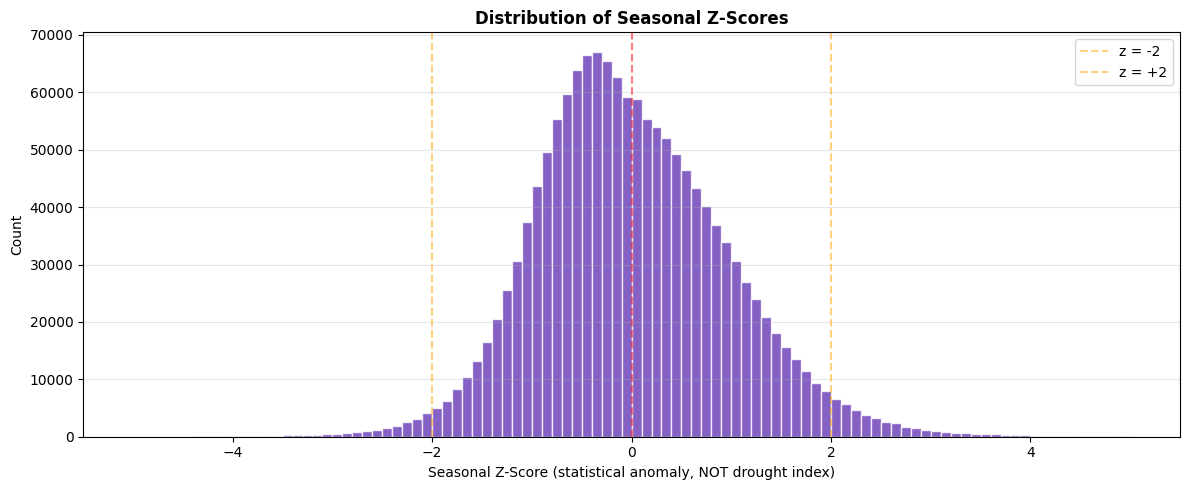

In [20]:
# Compute seasonal z-scores
india_z = compute_seasonal_z_score(india_seasonal, min_observations=5)
z_available = india_z[india_z['seasonal_z_score_available']]

print(f'Observations with z-score available: {len(z_available):,} / {len(india_z):,} '
      f'({len(z_available)/len(india_z)*100:.1f}%)')
print(f'Z-score stats: mean={z_available["seasonal_z_score"].mean():.4f}, '
      f'std={z_available["seasonal_z_score"].std():.4f}')
print()

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(z_available['seasonal_z_score'].clip(-5, 5), bins=100, 
        color='#673AB7', alpha=0.8, edgecolor='white')
ax.axvline(x=0, color='red', linestyle='--', alpha=0.5)
ax.axvline(x=-2, color='orange', linestyle='--', alpha=0.5, label='z = -2')
ax.axvline(x=2, color='orange', linestyle='--', alpha=0.5, label='z = +2')
ax.set_title('Distribution of Seasonal Z-Scores', fontweight='bold')
ax.set_xlabel('Seasonal Z-Score (statistical anomaly, NOT drought index)')
ax.set_ylabel('Count')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Baseline Analytics

Before any ML forecasting, we establish transparent baselines:
1. **Persistence baseline**: next value = previous value
2. **Seasonal historical baseline** (India): prediction = mean of prior years' same-season observations
3. **Maharashtra persistence baseline**: next 6-hourly value = previous value


In [21]:
from src.features.baselines import (
    compute_persistence_baseline, compute_seasonal_historical_baseline,
    compute_maharashtra_persistence_baseline, compute_baseline_evaluation_metrics
)

# India persistence baseline (sample for efficiency)
india_baseline_sample = india_seasonal[india_seasonal['candidate_site_id'].isin(sites_10plus[:2000])]
india_persist = compute_persistence_baseline(india_baseline_sample)

persist_metrics = compute_baseline_evaluation_metrics(
    india_persist['persistence_residual'], 'India Persistence'
)
print('=== INDIA PERSISTENCE BASELINE ===')
for k, v in persist_metrics.items():
    print(f'  {k}: {v}')


=== INDIA PERSISTENCE BASELINE ===
  baseline: India Persistence
  evaluable_observations: 108095
  mae: 2.0009
  rmse: 3.351
  median_ae: 1.2
  bias: 0.0211


In [22]:
# India seasonal historical baseline (sample)
india_sample_for_hist = india_seasonal[
    india_seasonal['candidate_site_id'].isin(sites_10plus[:500])
]
india_hist = compute_seasonal_historical_baseline(
    india_sample_for_hist, min_historical_years=3
)

hist_metrics = compute_baseline_evaluation_metrics(
    india_hist['seasonal_hist_residual'], 'India Seasonal Historical'
)
print('=== INDIA SEASONAL HISTORICAL BASELINE ===')
for k, v in hist_metrics.items():
    print(f'  {k}: {v}')
print(f'  Observations with baseline available: {india_hist["seasonal_hist_available"].sum():,}')


=== INDIA SEASONAL HISTORICAL BASELINE ===
  baseline: India Seasonal Historical
  evaluable_observations: 20453
  mae: 1.6618
  rmse: 2.9827
  median_ae: 0.925
  bias: 0.1781
  Observations with baseline available: 20,453


In [23]:
# Maharashtra persistence baseline
mh_persist = compute_maharashtra_persistence_baseline(mh_ar)

mh_persist_metrics = compute_baseline_evaluation_metrics(
    mh_persist['persistence_residual'], 'Maharashtra Persistence'
)
print('=== MAHARASHTRA PERSISTENCE BASELINE ===')
for k, v in mh_persist_metrics.items():
    print(f'  {k}: {v}')
print()
print('NOTE: Low MAE for Maharashtra persistence is expected since consecutive')
print('6-hourly readings of groundwater level change slowly.')


=== MAHARASHTRA PERSISTENCE BASELINE ===
  baseline: Maharashtra Persistence
  evaluable_observations: 209658
  mae: 0.3227
  rmse: 1.4891
  median_ae: 0.04
  bias: -0.0153

NOTE: Low MAE for Maharashtra persistence is expected since consecutive
6-hourly readings of groundwater level change slowly.


In [24]:
# Baseline comparison summary
print('=== BASELINE COMPARISON ===')
print(f'{"Baseline":<35s} {"MAE":>10s} {"RMSE":>10s} {"MedAE":>10s} {"Bias":>10s} {"N":>10s}')
print('-' * 85)
for m in [persist_metrics, hist_metrics, mh_persist_metrics]:
    name = m['baseline']
    mae = f"{m['mae']:.4f}" if m['mae'] is not None else 'N/A'
    rmse = f"{m['rmse']:.4f}" if m['rmse'] is not None else 'N/A'
    medae = f"{m['median_ae']:.4f}" if m['median_ae'] is not None else 'N/A'
    bias = f"{m['bias']:.4f}" if m['bias'] is not None else 'N/A'
    n = f"{m['evaluable_observations']:,}"
    print(f'{name:<35s} {mae:>10s} {rmse:>10s} {medae:>10s} {bias:>10s} {n:>10s}')


=== BASELINE COMPARISON ===
Baseline                                   MAE       RMSE      MedAE       Bias          N
-------------------------------------------------------------------------------------
India Persistence                       2.0009     3.3510     1.2000     0.0211    108,095
India Seasonal Historical               1.6618     2.9827     0.9250     0.1781     20,453
Maharashtra Persistence                 0.3227     1.4891     0.0400    -0.0153    209,658


## 12. Feature Quality/Readiness Summary


In [25]:
print('=== FEATURE QUALITY & READINESS SUMMARY ===')
print()
print('INDIA DATASET:')
print(f'  Total analytics-ready observations: {len(india_ar):,}')
print(f'  Unique analytical sites: {india_ar["candidate_site_id"].nunique():,}')
print(f'  Sites with >=10 observations: {(site_summary["total_observations"] >= 10).sum():,}')
print(f'  Sites with >=20 observations: {(site_summary["total_observations"] >= 20).sum():,}')
print(f'  Temporal span: ~30 years (1994-2024)')
print(f'  Observation frequency: ~quarterly (4 main seasons per year)')
print(f'  Seasonal features: AVAILABLE (4 main seasons well-represented)')
print(f'  Trend features: AVAILABLE for {len(trends):,} sites')
print(f'  Z-score features: AVAILABLE for {len(z_available):,} observations')
print(f'  Persistence baseline: AVAILABLE')
print(f'  Seasonal historical baseline: AVAILABLE')
print(f'  SGI: REJECTED (insufficient temporal regularity)')
print()
print('MAHARASHTRA DATASET:')
print(f'  Total analytics-ready observations: {len(mh_ar):,}')
print(f'  Unique stations: {mh_ar["station_name"].nunique():,}')
print(f'  Temporal span: ~5 months (Jan-May 2026)')
print(f'  Observation frequency: 6-hourly telemetry')
print(f'  Persistence baseline: AVAILABLE (low MAE expected)')
print(f'  Short-term lags: SUPPORTED (6h, 12h, 24h, 48h)')


=== FEATURE QUALITY & READINESS SUMMARY ===

INDIA DATASET:
  Total analytics-ready observations: 1,542,448
  Unique analytical sites: 40,841
  Sites with >=10 observations: 27,585
  Sites with >=20 observations: 23,004
  Temporal span: ~30 years (1994-2024)
  Observation frequency: ~quarterly (4 main seasons per year)
  Seasonal features: AVAILABLE (4 main seasons well-represented)
  Trend features: AVAILABLE for 26,162 sites
  Z-score features: AVAILABLE for 1,475,398 observations
  Persistence baseline: AVAILABLE
  Seasonal historical baseline: AVAILABLE
  SGI: REJECTED (insufficient temporal regularity)

MAHARASHTRA DATASET:
  Total analytics-ready observations: 210,670
  Unique stations: 1,012
  Temporal span: ~5 months (Jan-May 2026)
  Observation frequency: 6-hourly telemetry
  Persistence baseline: AVAILABLE (low MAE expected)
  Short-term lags: SUPPORTED (6h, 12h, 24h, 48h)


## 13. Limitations and Conclusions

### Key Findings

1. **India** has ~41,000 analytical sites with periodic quarterly observations spanning 30 years.
   The `candidate_site_id` provides a deterministic, reproducible analytical location key.
   Spatial clustering was evaluated and **rejected** as it would introduce unverifiable assumptions.

2. **Maharashtra** has ~1,014 DWLR stations with 6-hourly telemetry spanning ~5 months.
   Temporal continuity is good (median interval = 6 hours).

3. **SGI is not justified** due to irregular temporal sampling and incomplete coverage.
   A simpler `seasonal_z_score` provides a defensible alternative.

4. All temporal features are **strictly backward-looking** with no future leakage.

### Unresolved Scientific Uncertainties

- India water-level unit remains UNKNOWN.
- Reference datum is UNKNOWN for both datasets.
- `status_raw` and `trend_raw` provenance is unverified.
- Without datum information, trend slopes cannot be physically interpreted.
- The `candidate_site_id` is an analytical construct, not an official station ID.

### What This Means for Future Milestones

- Forecasting models must beat the persistence and seasonal baselines.
- Chronological train/validation/test splits are mandatory.
- India features are suited for seasonal/annual forecasting.
- Maharashtra features are suited for short-term (hours-to-days) forecasting.
